# Lab 7 – Responsible AI HS2026 (P07 Case Study)
**Author:** Jann Erhardt (erharjan) · individual submission

Scaffold only: fill in the `TODO`s yourself. Paste results/plots into the answer PDF (`Lab7_erharjan_template.pdf`).

The *Sanity checks* cells fail until the functions above them are implemented – they only test properties, not the lab results.

Setup cells are copied from the course Colab «Case Study.ipynb». Two deliberate changes: (1) Task 6 applies `preprocess_data()` to the 2018 data too (the Colab cell skips it, so ages < 25 / > 65 and other races would stay in); (2) decisions use `score > t`, like `model.predict()`.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BLACK, WHITE = 2, 1           # RAC1P codes
THRESHOLDS = np.round(np.linspace(0, 1, 101), 2)   # 0, 0.01, ..., 1.00
BIN_EDGES = np.linspace(0, 1, 11)                  # 10 score bins, last one closed [0.9, 1]

## Setup (from the course Colab)

In [23]:
# !pip install folktables   # Colab: once
training_state, training_year, training_horizon = 'PA', 2014, '1-Year'
deployment_state, deployment_year, deployment_horizon = 'PA', 2018, '1-Year'

In [24]:
def preprocess_data(features, label, group):
  # Age
  ix_right_age_group = (features[:,0]>=25) & (features[:,0]<=65)
  features = features[ix_right_age_group]
  label = label[ix_right_age_group]
  group = group[ix_right_age_group]
  # Race
  ix_bw = (group==1) | (group==2)
  features = features[ix_bw]
  label = label[ix_bw]
  group = group[ix_bw]

  return (features, label, group)

In [25]:
from folktables import ACSDataSource, ACSEmployment
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data_source = ACSDataSource(survey_year=training_year, horizon=training_horizon, survey='person')
acs_data = data_source.get_data(states=[training_state], download=True)
features, label, group = ACSEmployment.df_to_numpy(acs_data)
features, label, group = preprocess_data(features, label, group)

X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(
    features, label, group, test_size=0.2, random_state=0)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

yhat = model.predict(X_test)
scores = model.predict_proba(X_test)[:,1]
print(np.mean(label))   # Colab: 0.710... (the sheet's story says 66 % – decide which one you use in task 3 and say so in the PDF)

0.710184182015168


## 1. Model quality: accuracy and calibration

In [34]:
def accuracy(y, score, t=0.5):
    """Share of correct decisions D = 1 iff score > t (like model.predict() at t = 0.5)."""
    return np.mean((score > t) == y)


def calibration_table(score, y, edges=BIN_EDGES, z=1.96):
    """One row per bin: n, mean score x_i, actual rate y_i, ci_low, ci_high (95 % CI of y_i).
    Bins [a, b) except the last one [0.9, 1]. Empty bins -> n = 0, NaN values."""
    bins = np.digitize(score, edges, right=False)
    df = pd.DataFrame({'score': score, 'y': y, 'bin': bins})
    tab = df.groupby('bin').agg({'score': ['count', 'mean'], 'y': 'mean'}).reset_index()
    tab.columns = ['bin', 'n', 'mean_score', 'actual_rate']
    tab['ci_low'] = tab['actual_rate'] - z * np.sqrt(tab['actual_rate'] * (1 - tab['actual_rate']) / tab['n'])
    tab['ci_high'] = tab['actual_rate'] + z * np.sqrt(tab['actual_rate'] * (1 - tab['actual_rate']) / tab['n'])
    return tab


def plot_calibration(tables, labels, ax=None):
    """x: mean score, y: actual rate with error bars (95 % CI), diagonal = perfect calibration."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    for tab, label in zip(tables, labels):
        ax.errorbar(tab['mean_score'], tab['actual_rate'],
                    yerr=[tab['actual_rate'] - tab['ci_low'], tab['ci_high'] - tab['actual_rate']],
                    fmt='o-', label=label)
    ax.plot([0, 1], [0, 1], 'k--', label='perfect calibration')
    ax.set_xlabel('Mean score')
    ax.set_ylabel('Actual rate')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()

In [27]:
accuracy(y_test, scores)

np.float64(0.7649744621575607)

In [28]:
table = calibration_table(scores, y_test)
table

,bin,n,mean_score,actual_rate,ci_low,ci_high
0,1,192,0.057417,0.098958,0.056720,0.141196
1,2,292,0.153545,0.157534,0.115748,0.199320
2,3,420,0.248958,0.252381,0.210838,0.293924
3,4,448,0.351937,0.366071,0.321463,0.410680
4,5,396,0.449080,0.446970,0.398001,0.495939
5,6,701,0.559585,0.493581,0.456570,0.530592
6,7,1778,0.654655,0.649606,0.627430,0.671783
7,8,3278,0.754795,0.764491,0.749965,0.779016
8,9,4405,0.850354,0.842906,0.832160,0.853652
9,10,1012,0.918412,0.917984,0.901079,0.934890


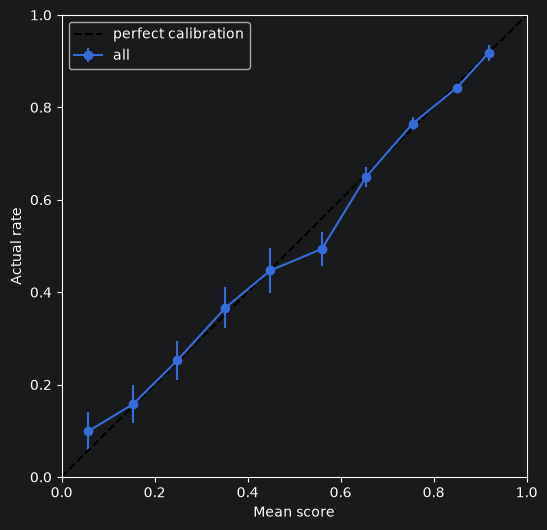

In [35]:
plot_calibration([table], ['all'])

### Sanity checks (1)

In [30]:
rng = np.random.default_rng(1)
s = rng.uniform(0, 1, 50_000); y = (rng.uniform(0, 1, s.size) < s).astype(int)   # perfectly calibrated by construction
tab = calibration_table(s, y)
assert len(tab) == 10 and tab['n'].sum() == s.size
assert np.allclose(tab['mean_score'], tab['actual_rate'], atol=0.03)
assert ((tab['ci_low'] <= tab['actual_rate']) & (tab['actual_rate'] <= tab['ci_high'])).all()
assert (tab['ci_high'] - tab['ci_low']).max() < 0.05          # large n -> narrow CI
assert calibration_table(np.array([1.0, 1.0]), np.array([1, 0]))['n'].iloc[-1] == 2   # score 1.0 lands in the last bin
assert accuracy(np.array([1, 0, 1, 0]), np.array([0.9, 0.1, 0.4, 0.6])) == 0.5
print('ok')

ok


## 2. Two groups

In [38]:
def group_rates(y, d):
    """dict with BR, PR, TPR, FNR, FPR, TNR for labels y and decisions d (arrays of 0/1)."""
    return {
        'BR': np.mean(y),
        'PR': np.mean(d),
        'TPR': np.sum((y == 1) & (d == 1)) / np.sum(y == 1) if np.sum(y == 1) > 0 else np.nan,
        'FNR': np.sum((y == 1) & (d == 0)) / np.sum(y == 1) if np.sum(y == 1) > 0 else np.nan,
        'FPR': np.sum((y == 0) & (d == 1)) / np.sum(y == 0) if np.sum(y == 0) > 0 else np.nan,
        'TNR': np.sum((y == 0) & (d == 0)) / np.sum(y == 0) if np.sum(y == 0) > 0 else np.nan
    }


def two_prop_pvalue(k1, n1, k2, n2):
    """Two-sided p-value for H0: p1 == p2 (two-proportion test)."""
    p1, p2 = k1 / n1, k2 / n2
    p = (k1 + k2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    return 2 * (1 - stats.norm.cdf(abs(z)))


def compare_groups(y, d, race):
    """DataFrame: metric x (Black, White, difference, p_value) – the p-value must use the right n per metric
    (e.g. TPR is a share of the Y=1 individuals, not of everybody)."""
    metrics = ['BR', 'PR', 'TPR', 'FNR', 'FPR', 'TNR']
    results = []
    for metric in metrics:
        mask_black = (race == BLACK)
        mask_white = (race == WHITE)
        rates_black = group_rates(y[mask_black], d[mask_black])
        rates_white = group_rates(y[mask_white], d[mask_white])
        k1, n1 = (np.sum((y[mask_black] == 1) & (d[mask_black] == 1)), np.sum(y[mask_black] == 1)) if metric in ['TPR', 'FNR'] else (np.sum((y[mask_black] == 0) & (d[mask_black] == 1)), np.sum(y[mask_black] == 0)) if metric in ['FPR', 'TNR'] else (np.sum(d[mask_black]), len(d[mask_black])) if metric == 'BR' else (np.sum(y[mask_black]), len(y[mask_black]))
        k2, n2 = (np.sum((y[mask_white] == 1) & (d[mask_white] == 1)), np.sum(y[mask_white] == 1)) if metric in ['TPR', 'FNR'] else (np.sum((y[mask_white] == 0) & (d[mask_white] == 1)), np.sum(y[mask_white] == 0)) if metric in ['FPR', 'TNR'] else (np.sum(d[mask_white]), len(d[mask_white])) if metric == 'BR' else (np.sum(y[mask_white]), len(y[mask_white]))
        p_value = two_prop_pvalue(k1, n1, k2, n2)
        results.append({
            'metric': metric,
            'Black': rates_black[metric],
            'White': rates_white[metric],
            'difference': rates_black[metric] - rates_white[metric],
            'p_value': p_value
        })
    return pd.DataFrame(results)

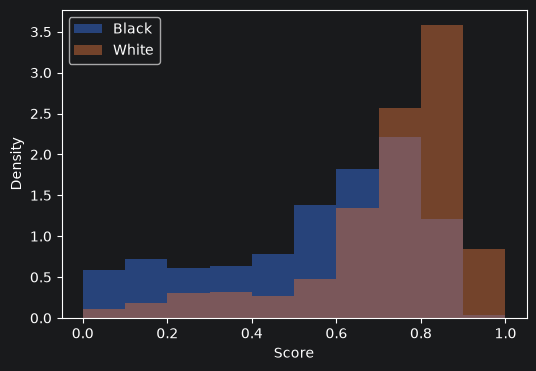

In [42]:
# score distributions per group (hist, same bins),

ax, fig = plt.subplots(figsize=(6, 4))
plt.hist(scores[group_test == BLACK], bins=BIN_EDGES, alpha=0.5, label='Black', density=True)
plt.hist(scores[group_test == WHITE], bins=BIN_EDGES, alpha=0.5, label='White', density=True)
plt.xlabel('Score')
plt.ylabel('Density')
plt.legend()
plt.show()

In [53]:
bins = np.digitize(scores, BIN_EDGES, right=False)
rows = []

for bin_number in range(1, len(BIN_EDGES)):
    black = (group_test == BLACK) & (bins == bin_number)
    white = (group_test == WHITE) & (bins == bin_number)
    n_black = np.sum(black)
    n_white = np.sum(white)
    k_black = np.sum(y_test[black])
    k_white = np.sum(y_test[white])
    actual_rate_black = k_black / n_black if n_black else np.nan
    actual_rate_white = k_white / n_white if n_white else np.nan
    p_value = two_prop_pvalue(k_black, n_black, k_white, n_white) if n_black and n_white else np.nan
    rows.append({
        'bin': bin_number,
        'N Black': n_black,
        'actual rate Black': actual_rate_black,
        'N White': n_white,
        'actual rate White': actual_rate_white,
        'p-value': p_value
    })

pd.DataFrame(rows)

,bin,N Black,actual rate Black,N White,actual rate White,p-value
0,1,57,0.140351,135,0.081481,0.211999
1,2,70,0.142857,222,0.162162,0.699066
2,3,59,0.305085,361,0.243767,0.314781
3,4,62,0.225806,386,0.388601,0.013513
4,5,76,0.328947,320,0.475000,0.021328
5,6,134,0.470149,567,0.499118,0.546356
6,7,177,0.598870,1601,0.655215,0.135967
7,8,215,0.804651,3063,0.761672,0.151091
8,9,118,0.872881,4287,0.842081,0.364376
9,10,3,0.666667,1009,0.918731,0.112112


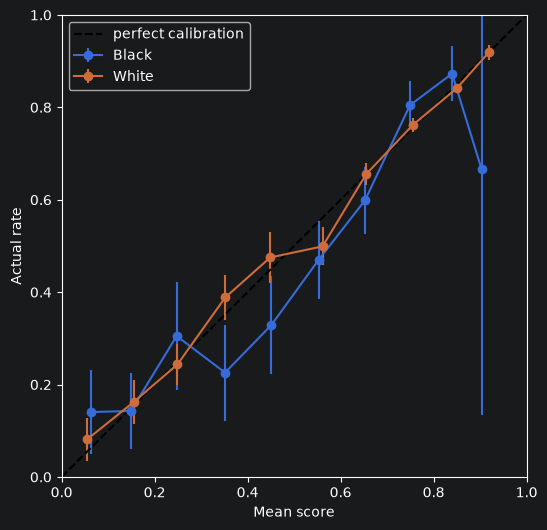

In [52]:
# calibration per group (reuse calibration_table), per-bin test Black vs White (actual rates), compare_groups(y_test, (scores > 0.5).astype(int), group_test)
tabs = [calibration_table(scores[group_test == BLACK], y_test[group_test == BLACK]),
        calibration_table(scores[group_test == WHITE], y_test[group_test == WHITE])]
plot_calibration(tabs, ['Black', 'White'])

In [54]:
compare_groups(y_test, (scores > 0.5).astype(int), group_test)

,metric,Black,White,difference,p_value
0,BR,0.537590,0.722868,-0.185278,0.0
1,PR,0.666323,0.880847,-0.214523,0.0
2,TPR,0.856322,0.949415,-0.093094,0.0
3,FNR,0.143678,0.050585,0.093094,0.0
4,FPR,0.445434,0.701993,-0.256558,0.0
5,TNR,0.554566,0.298007,0.256558,0.0


### Sanity checks (2)

In [44]:
yy = np.array([1, 1, 1, 0, 0, 0, 0, 1]); dd = np.array([1, 1, 0, 1, 0, 0, 0, 0])
r = group_rates(yy, dd)
assert np.isclose(r['BR'], 0.5) and np.isclose(r['PR'], 3 / 8)
assert np.isclose(r['TPR'], 2 / 4) and np.isclose(r['FPR'], 1 / 4)
assert np.isclose(r['TPR'] + r['FNR'], 1) and np.isclose(r['FPR'] + r['TNR'], 1)
assert two_prop_pvalue(50, 100, 50, 100) > 0.99
assert two_prop_pvalue(10, 1000, 200, 1000) < 1e-6
assert 0 <= two_prop_pvalue(3, 10, 6, 10) <= 1
print('ok')

ok


## 3. Utility of the decision maker

In [59]:
def dm_utility_matrix():
    """U[d, y] in CHF k over the two years after the decision (negative = cost for the taxpayers)."""
    return np.array([
        [-60, -60],   # D=0: unemployed both years (2 x 30), whatever Y is
        [-80, -50],   # D=1, Y=0: 20 + 30 (year 1) + 30 (year 2); D=1, Y=1: 20 + 30 (year 1) + 0 (year 2)
    ])


def total_utility(y, d, U):
    """Sum of U[d_i, y_i] over all individuals."""
    return np.sum(U[np.asarray(d, dtype=int), np.asarray(y, dtype=int)])


def theoretical_threshold(U):
    """Break-even P[Y=1]: E[U | D=1] = E[U | D=0]. The gap a + b*p is linear in p."""
    a = U[1, 0] - U[0, 0]                  # gap at p = 0
    b = (U[1, 1] - U[0, 1]) - a            # slope
    if b <= 0:
        raise ValueError('D=1 does not become better as p grows - check the matrix')
    return float(np.clip(-a / b, 0, 1))    # <0: always D=1, >1: never D=1


def best_threshold(score, y, U, thresholds=THRESHOLDS):
    """(threshold, total utility) maximizing the total utility on the data (D = 1 iff score > t)."""
    best_t, best_u = None, -np.inf
    for t in thresholds:
        u = total_utility(y, (score > t).astype(int), U)
        if u > best_u:
            best_t, best_u = t, u
    return best_t, best_u

### Sanity checks (3)

In [60]:
U_toy = np.array([[0., -5.], [-2., 3.]])   # toy matrix, NOT the lab's
assert total_utility(np.array([0, 1, 1, 0]), np.array([0, 1, 0, 1]), U_toy) == 0 + 3 + -5 + -2
assert np.isclose(theoretical_threshold(U_toy), 0.2)   # E[U|D=1] = 5p - 2, E[U|D=0] = -5p
sc = np.array([0.1, 0.4, 0.6, 0.9]); yv = np.array([0, 0, 1, 1])
t, u = best_threshold(sc, yv, np.array([[0., 0.], [-1., 1.]]))   # accept exactly the Y=1 cases
assert 0.4 <= t < 0.6 and u == 2   # D = 1 iff score > t
print('ok')

ok


In [61]:
# TODO:
#       plot total utility vs. threshold
U = dm_utility_matrix()
theory = theoretical_threshold(U)
t_star, u_star = best_threshold(scores, y_test, U)
print(f'Theoretical threshold: {theory:.2f}, Best threshold: {t_star:.2f}, Best utility: {u_star:.2f}')

Theoretical threshold: 0.67, Best threshold: 0.66, Best utility: -734230.00


## 4. Fairness criterion (after you have chosen V and J in the PDF)

In [ ]:
V = np.array([
    [0, 0],
    [0, 1]
])
J = None   # TODO: name of the justifier column / None; morally relevant values


def group_benefit(y, d, mask, V, justifier_mask=None):
    """E(V | group[, J=j]) – average V[d_i, y_i] over the individuals in `mask` (optionally restricted to J=j). TODO"""
    raise NotImplementedError


def fairness_metric(y, d, race, V, justifier_mask=None):
    """FM = E(V | J=j, A=Black) - E(V | J=j, A=White). TODO"""
    raise NotImplementedError

In [ ]:
# TODO: FM at the best single threshold from task 3 + significance of the difference (bootstrap or test; name it in the PDF)

## 5. Pareto plot (101 x 101 group-specific thresholds)

In [ ]:
def evaluate_grid(score, y, race, U, V, thresholds=THRESHOLDS):
    """DataFrame with columns t_black, t_white, EU, FM for all len(thresholds)**2 pairs. TODO (vectorize – 10 201 pairs)"""
    raise NotImplementedError


def pareto_front(results, x, y):
    """Rows no other row dominates. Decide which direction of FM is «better» (|FM| small!) and say so in the PDF. TODO"""
    raise NotImplementedError

### Sanity checks (5)

In [ ]:
toy = pd.DataFrame({'name': list('ABCDE'), 'unfair': [0.3, 0.1, 0.0, 0.2, 0.3], 'EU': [10., 8., 5., 7., 6.]})
toy['fair'] = -toy['unfair']
assert set(pareto_front(toy, x='fair', y='EU')['name']) == {'A', 'B', 'C'}
print('ok')

In [ ]:
# TODO: res = evaluate_grid(...); front = pareto_front(res, ...); scatter + highlight frontier; pick (t_black, t_white)

## 6. Four years later (2018 data, model from 2014)
Re-run 1–5 on `label_deploy, group_deploy, scores_deploy` – no new split. Keep `U` and the fairness criterion fixed.

In [ ]:
data_source_deploy = ACSDataSource(survey_year=deployment_year, horizon=deployment_horizon, survey='person')
acs_deploy = data_source_deploy.get_data(states=[deployment_state], download=True)
features_deploy, label_deploy, group_deploy = ACSEmployment.df_to_numpy(acs_deploy)
# NB: the Colab skips this line – without it ages < 25 / > 65 and other races are evaluated too
features_deploy, label_deploy, group_deploy = preprocess_data(features_deploy, label_deploy, group_deploy)

yhat_deploy = model.predict(features_deploy)
scores_deploy = model.predict_proba(features_deploy)[:,1]

In [ ]:
# TODO: reuse the functions above with (scores_deploy, label_deploy, group_deploy); compare against the 2014 test-set results